Data retrieved from frost.met.no!


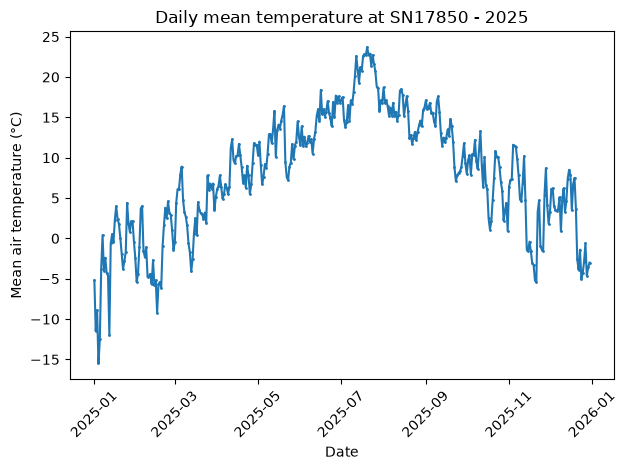

Statistic  Temperature (°C)
     Mean               7.9
   Median               8.4
      Min             -15.5
      Max              23.7


In [6]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

with open("ID.txt") as f:
    client_id = f.read().strip()

endpoint = 'https://frost.met.no/observations/v0.jsonld'

parameters = {
    'sources': 'SN17850',
    'elements': 'mean(air_temperature P1D)',
    'referencetime': '2025-01-01/2025-12-31',
}

response = requests.get(
    endpoint,
    params=parameters,
    auth=(client_id, '')
)

json_data = response.json()

if response.status_code == 200:
    data = json_data['data']

    print('Data retrieved from frost.met.no!')

    rows = []

    for item in data:
        row = pd.DataFrame(item['observations'])
        row['referenceTime'] = item['referenceTime']
        row['sourceId'] = item['sourceId']
        rows.append(row)

    df = pd.concat(rows, ignore_index=True)

    # The original data contains multiple time offsets, we keep only one daily time offset
    df = df[df['timeOffset'] == 'PT0H'].copy()

    # Convert timestamps so they can be sorted and plotted as dates
    df['referenceTime'] = pd.to_datetime(df['referenceTime'])

    # Sort chronologically
    df = df.sort_values('referenceTime')

    # Define x and y values
    xpoints = df['referenceTime']
    ypoints = df['value']

    plt.plot(xpoints, ypoints, marker='.', markersize=2)

    plt.xlabel('Date')
    plt.ylabel('Mean air temperature (°C)')
    plt.title('Daily mean temperature at SN17850 - 2025')
    
    plt.xticks(rotation=45)
    plt.tight_layout()

    plt.show()

    mean_temp = df['value'].mean()
    median_temp = df['value'].median()
    min_temp = df['value'].min()
    max_temp = df['value'].max()

    summary = pd.DataFrame({
        'Statistic': ['Mean', 'Median', 'Min', 'Max'],
        'Temperature (°C)': [mean_temp.round(2),
        median_temp.round(2),
        min_temp.round(2),
        max_temp.round(2)]
    })

    print(summary.to_string(index=False))

else:
    print(f'Error! Returned status code {response.status_code}')
    print(f"Message: {json_data['error']['message']}")
    print(f"Reason: {json_data['error']['reason']}")